# STAR hardware and resource models

A short tour of `qec_star.hardware`: the noise model, the scenario registry, the cycle-time model and
the resource accounting. Change the values in the **Parameters** cell and rerun.

Everything computed here is exact counting or closed-form arithmetic. Nothing in this notebook
depends on a decoder, except the last section, which only *displays* recorded sampling results and
labels them provisional.

Setup: `python -m pip install -e '.[dev]'` from the repository root, plus `jupyter` to run this file.

## Parameters

In [1]:
LOGICAL_QUBITS = 64          # logical qubits to store
SURFACE_DISTANCE = 9         # rotated surface code distance (paper: 9)
BICYCLE_L = 4                # bicycle-chain block [[14 l, 2 l, 6]] (paper: l = 4, k = 8)
SCENARIO = "paper/p1e-3"     # any id printed in the registry table below
ROUNDS = 6                   # rounds of the small memory circuit used for the noise audit

# Cycle-time model, in microseconds. The paper gives only totals (1 ms and 2 ms);
# these defaults reproduce them as 0.25 ms per entangling layer with no fixed term.
PER_LAYER_US = 250.0         # gate + transport per entangling layer
FIXED_US = 0.0               # readout + reset + anything else that happens once per round
T2_MS = 1500.0               # coherence time used for the idle-error estimate

In [2]:
import json
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt

from qec_star.circuits import memory_experiment
from qec_star.hardware import (SCENARIOS, CycleTiming, allocate, bicycle_block, break_even_cycle_ratio,
                               dephasing_probability, memory_spacetime_ratio, star_data_qubits,
                               star_resources, surface_block)
from qec_star.hardware.noise import decorate_stim_memory, expected_faults, noise_census

BLUE, ORANGE = "#257de0", "#f47230"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "figure.dpi": 110})

## 1. Scenario registry

Each scenario fixes the error probabilities and cycle times and says where they come from.
`paper/p1e-3` is the reproduction target; everything else is exploratory.

In [3]:
print(f"{'id':26} {'kind':12} {'2q':>8} {'meas':>8} {'idle':>8} {'cycle idle':>11}  cycle ms (surface/bicycle)")
for sid, s in SCENARIOS.items():
    n = s.noise
    print(f"{sid:26} {s.kind:12} {n.two_qubit:8.2e} {n.measurement:8.2e} {n.idle:8.2e} {n.cycle_idle:11.2e}"
          f"  {s.cycle_ms('surface'):g} / {s.cycle_ms('bicycle'):g}")

id                         kind               2q     meas     idle  cycle idle  cycle ms (surface/bicycle)
paper/p1e-3                reference    1.00e-03 1.00e-03 1.00e-03    0.00e+00  1 / 2
uniform/p0.0005            exploratory  5.00e-04 5.00e-04 5.00e-04    0.00e+00  1 / 2
uniform/p0.002             exploratory  2.00e-03 2.00e-03 2.00e-03    0.00e+00  1 / 2
uniform/p0.003             exploratory  3.00e-03 3.00e-03 3.00e-03    0.00e+00  1 / 2
uniform/p0.005             exploratory  5.00e-03 5.00e-03 5.00e-03    0.00e+00  1 / 2
asym/two_qubit_x0.5        exploratory  5.00e-04 1.00e-03 1.00e-03    0.00e+00  1 / 2
asym/two_qubit_x2          exploratory  2.00e-03 1.00e-03 1.00e-03    0.00e+00  1 / 2
asym/two_qubit_x4          exploratory  4.00e-03 1.00e-03 1.00e-03    0.00e+00  1 / 2
asym/measurement_x0.5      exploratory  1.00e-03 5.00e-04 1.00e-03    0.00e+00  1 / 2
asym/measurement_x2        exploratory  1.00e-03 2.00e-03 1.00e-03    0.00e+00  1 / 2
asym/measurement_x4        explor

In [4]:
scenario = SCENARIOS[SCENARIO]
print(scenario.description)
print("source:", scenario.source, "|", scenario.source_version)
print("evidence:", dict(scenario.evidence))
print("limitations:", scenario.limitations)

Paper baseline: uniform p = 1e-3, cycles 1 ms / 2 ms.
source: Ismail et al., arXiv:2606.25011 | v1 (2026-06-23), Sec. III, III.2, Table 4
evidence: {'prep': 'assumed', 'one_qubit': 'assumed', 'two_qubit': 'assumed', 'measurement': 'assumed', 'idle': 'assumed', 'cycle_idle': 'assumed', 'cycle_time': 'assumed'}
limitations: Uniform depolarizing model; no atom loss, leakage, transport error, crosstalk or noise bias. Cycle times are assumed totals; the paper gives no gate, movement or readout durations.


## 2. Adding noise to the team's circuit

`decorate_stim_memory` copies the noiseless circuit and inserts tagged noise channels. Measurement
records, detectors and observables are untouched.

In [5]:
clean = memory_experiment(BICYCLE_L, 7, ROUNDS, basis="Z")
noisy = decorate_stim_memory(clean, scenario.noise)
assert noisy.without_noise() == clean.flattened()
print("detectors:", clean.num_detectors, "->", noisy.num_detectors,
      "| observables:", clean.num_observables, "->", noisy.num_observables)
print("noise locations:", dict(noise_census(noisy)))
print("expected faults per shot:", {k: round(v, 4) for k, v in expected_faults(noisy, scenario.noise).items()})
print()
print("\n".join(str(noisy).splitlines()[4 * BICYCLE_L * 7 :][:9]))

detectors: 336 -> 336 | observables: 8 -> 8
noise locations: {'prep': 392, 'two_qubit': 2688, 'measurement': 392}
expected faults per shot: {'prep': 0.392, 'two_qubit': 2.688, 'measurement': 0.392}

R 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55
DEPOLARIZE1[prep](0.001) 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55
TICK
RX 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83
DEPOLARIZE1[prep](0.001) 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83
R 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99 100 101 102 103 104 105 106 107 108 109 110 111
DEPOLARIZE1[prep](0.001) 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99 100 101 102 103 104 105 106 107 108 109 110 111
TICK
CX 56 11 28 84 57 12 29 85 58 13 

### Where the faults are, per logical qubit per round

Exact counts from two circuits that differ by one round. The surface circuit is Stim's generated
rotated memory circuit, a stand-in until the team's surface-code circuit exists.

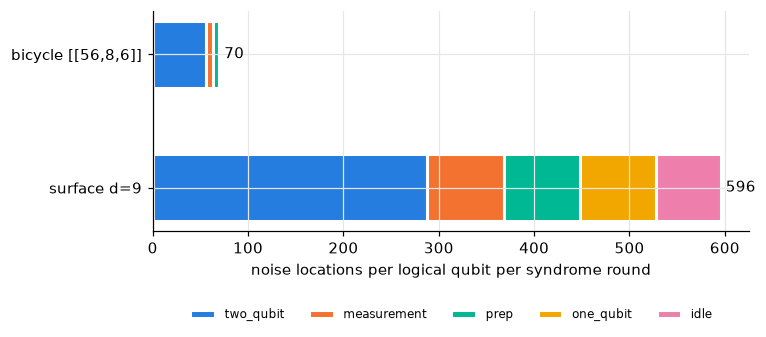

surface d=9 {'two_qubit': 288.0, 'measurement': 80.0, 'prep': 80.0, 'one_qubit': 80.0, 'idle': 68.0} two-qubit share: 48%
bicycle [[56,8,6]] {'two_qubit': 56.0, 'measurement': 7.0, 'prep': 7.0, 'one_qubit': 0.0, 'idle': 0.0} two-qubit share: 80%


In [6]:
import stim

def per_round(make, logical):
    a, b = (noise_census(decorate_stim_memory(make(r), SCENARIOS["idle/t2_150ms/surface"].noise)) for r in (3, 4))
    return {c: (b[c] - a[c]) / logical for c in ("two_qubit", "measurement", "prep", "one_qubit", "idle")}

surface, bicycle = surface_block(SURFACE_DISTANCE), bicycle_block(BICYCLE_L)
budget = {
    f"surface d={SURFACE_DISTANCE}": per_round(lambda r: stim.Circuit.generated(
        "surface_code:rotated_memory_z", distance=SURFACE_DISTANCE, rounds=r), surface.logical),
    f"bicycle [[{bicycle.data},{bicycle.logical},6]]": per_round(
        lambda r: memory_experiment(BICYCLE_L, 7, r), bicycle.logical),
}
fig, ax = plt.subplots(figsize=(7, 2.6))
left = [0.0, 0.0]
for channel, colour in zip(("two_qubit", "measurement", "prep", "one_qubit", "idle"),
                           (BLUE, ORANGE, "#00b894", "#f2a600", "#ee7fac")):
    values = [budget[k][channel] for k in budget]
    ax.barh(list(budget), values, left=left, color=colour, edgecolor="white", linewidth=2, height=0.5, label=channel)
    left = [x + y for x, y in zip(left, values)]
for y, total in enumerate(left):
    ax.text(total + 5, y, f"{total:g}", va="center")
ax.set_xlabel("noise locations per logical qubit per syndrome round")
ax.legend(frameon=False, ncols=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.3))
plt.show()
for name, row in budget.items():
    print(name, {k: v for k, v in row.items()}, "two-qubit share:", f"{row['two_qubit'] / sum(row.values()):.0%}")

## 3. Cycle time

`cycle = layers x (gate + transport) + fixed`. Each duration is the wall-clock time of one parallel
layer, never a sum over atoms. With a fixed term (readout, reset), the bicycle/surface ratio drops
below the paper's 2.

surface cycle 1 ms, bicycle cycle 2 ms, ratio 2
bicycle breakdown (us): {'entangling': 0.0, 'movement': 2000.0, 'single_qubit': 0.0, 'measurement': 0.0, 'reset': 0.0, 'fixed_overhead': 0.0}
idle Z-error over one surface cycle at T2 = 1500 ms: 3.33e-04
idle Z-error over one bicycle cycle at T2 = 1500 ms: 6.66e-04


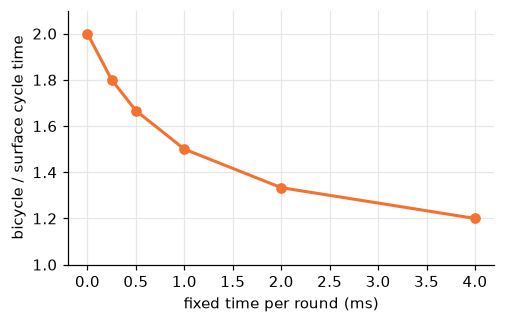

In [7]:
surface_cycle = CycleTiming(4, 0.0, PER_LAYER_US, FIXED_US)
bicycle_cycle = CycleTiming(8, 0.0, PER_LAYER_US, FIXED_US)
ratio = bicycle_cycle.cycle_us / surface_cycle.cycle_us
print(f"surface cycle {surface_cycle.cycle_ms:g} ms, bicycle cycle {bicycle_cycle.cycle_ms:g} ms, ratio {ratio:.3g}")
print("bicycle breakdown (us):", bicycle_cycle.breakdown_us())
for name, t in (("surface", surface_cycle), ("bicycle", bicycle_cycle)):
    print(f"idle Z-error over one {name} cycle at T2 = {T2_MS:g} ms: {dephasing_probability(t.cycle_us, T2_MS * 1000):.2e}")

fixed = [0, 250, 500, 1000, 2000, 4000]
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot([f / 1000 for f in fixed],
        [CycleTiming(8, 0, PER_LAYER_US, f).cycle_us / CycleTiming(4, 0, PER_LAYER_US, f).cycle_us for f in fixed],
        color=ORANGE, marker="o", linewidth=2)
ax.set_xlabel("fixed time per round (ms)"); ax.set_ylabel("bicycle / surface cycle time"); ax.set_ylim(1, 2.1)
plt.show()

## 4. Memory footprint and break-even

Exact atom counts for whole code blocks: data qubits plus one ancilla per check. No magic-state
space and no spare atoms. The ratio compares the codes as the paper pairs them (surface d = 9,
bicycle d = 6); it is not a comparison at equal logical error.

surface : 64 patches, 10304 atoms
bicycle : 8 blocks,  896 atoms, 0 unused logical qubits
qubit ratio 11.5
qubit-seconds per round ratio at the chosen cycle times: 5.75
break-even: the bicycle cycle may be up to 11.5x the surface cycle


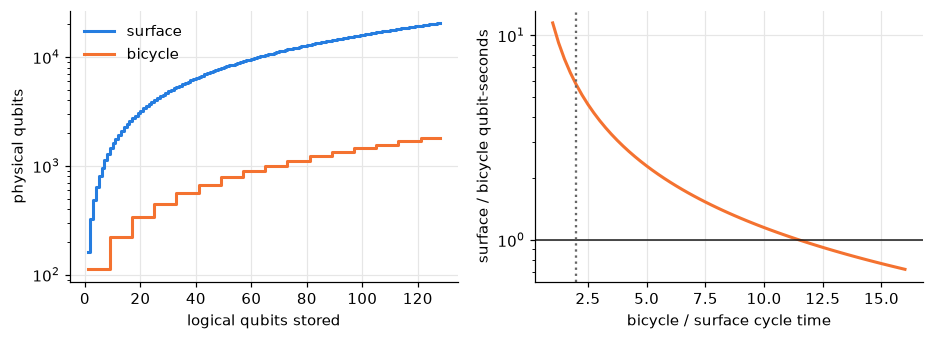

In [8]:
s_alloc, b_alloc = allocate(LOGICAL_QUBITS, surface), allocate(LOGICAL_QUBITS, bicycle)
print(f"surface : {s_alloc.blocks} patches, {s_alloc.physical} atoms")
print(f"bicycle : {b_alloc.blocks} blocks,  {b_alloc.physical} atoms, {b_alloc.unused_logical} unused logical qubits")
print(f"qubit ratio {s_alloc.physical / b_alloc.physical:.3g}")
print("qubit-seconds per round ratio at the chosen cycle times:",
      f"{memory_spacetime_ratio(LOGICAL_QUBITS, surface, bicycle, surface_cycle.cycle_ms, bicycle_cycle.cycle_ms):.3g}")
star = break_even_cycle_ratio(LOGICAL_QUBITS, surface, bicycle)
print(f"break-even: the bicycle cycle may be up to {star:.3g}x the surface cycle")

counts = range(1, 129)
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.2))
a.step(counts, [allocate(n, surface).physical for n in counts], where="post", color=BLUE, linewidth=2, label="surface")
a.step(counts, [allocate(n, bicycle).physical for n in counts], where="post", color=ORANGE, linewidth=2, label="bicycle")
a.set_yscale("log"); a.set_xlabel("logical qubits stored"); a.set_ylabel("physical qubits"); a.legend(frameon=False)
ratios = [r / 4 for r in range(4, 65)]
b.plot(ratios, [star / r for r in ratios], color=ORANGE, linewidth=2)
b.axhline(1, color="#191919", linewidth=1); b.axvline(ratio, color="#666666", linestyle=":")
b.set_yscale("log"); b.set_xlabel("bicycle / surface cycle time"); b.set_ylabel("surface / bicycle qubit-seconds")
plt.show()

## 5. End-to-end formulas (paper Appendix D.5)

    Q_phys = 2 (Q_data + Q_magic)
    t_run  = (V_RZ / Q_magic + V_Cliff / Q_data) x t_cycle

**The volumes below are arbitrary placeholders so the cell runs. They are not the paper's values and
not results.** `q_magic = 504` was picked so that Q_phys equals the paper's smallest reported
footprint (1,904), which shows how that number decomposes under Eq. (32); the runtime printed here
means nothing. Replace all three with the algorithm owner's numbers.

In [9]:
ILLUSTRATIVE = dict(v_rz=2.0e7, v_cliff=5.0e7, q_magic=504)   # placeholders, NOT results
q_data = star_data_qubits(LOGICAL_QUBITS, bicycle)
one = star_resources(q_data=q_data, cycle_ms=bicycle_cycle.cycle_ms, **ILLUSTRATIVE)
two = star_resources(q_data=q_data, cycle_ms=bicycle_cycle.cycle_ms, parallel_shots=2, **ILLUSTRATIVE)
for name, r in (("one instance", one), ("two instances", two)):
    print(f"{name:14}: {r.physical_qubits} atoms, latency {r.wall_seconds:.1f} s, "
          f"{r.seconds_per_shot:.1f} s per shot, {r.qubit_seconds_per_shot:.3g} qubit-seconds per shot")

one instance  : 1904 atoms, latency 302.6 s, 302.6 s per shot, 5.76e+05 qubit-seconds per shot
two instances : 3808 atoms, latency 302.6 s, 151.3 s per shot, 5.76e+05 qubit-seconds per shot


## 6. Recorded sampling results (provisional)

Shown for completeness. These depend on the decoder and, for the surface code, on a stand-in
circuit. They are not a reproduction of the paper's logical error rates. See `RESULTS.md`.

In [10]:
results = Path("../../results/udaya")
for name in ("validation_tesseract.jsonl", "pilot_bposd0_sequential.jsonl"):
    path = results / name
    if not path.exists():
        continue
    print(name)
    for line in path.read_text().splitlines():
        r = json.loads(line)
        if r["basis"] == "Z":
            print(f"  {r['scenario_id']:16} {r['architecture']:18} {str(r['code']):8} "
                  f"{r['failures']:>4}/{r['shots']:<6} 95% [{r['wilson95'][0]:.2e}, {r['wilson95'][1]:.2e}]")

validation_tesseract.jsonl
  paper/p1e-3      bicycle            [3, 7]      0/6000   95% [0.00e+00, 6.40e-04]
  paper/p1e-3      surface_reference  [5]         8/40000  95% [1.01e-04, 3.95e-04]
  paper/p1e-3      surface_reference  [7]         0/40000  95% [0.00e+00, 9.60e-05]
  paper/p1e-3      surface_reference  [9]         0/40000  95% [0.00e+00, 9.60e-05]
  uniform/p0.002   bicycle            [3, 7]      2/2400   95% [2.29e-04, 3.03e-03]
  uniform/p0.002   surface_reference  [5]        39/40000  95% [7.13e-04, 1.33e-03]
  uniform/p0.002   surface_reference  [7]         2/40000  95% [1.37e-05, 1.82e-04]
  uniform/p0.002   surface_reference  [9]         1/40000  95% [4.41e-06, 1.42e-04]
pilot_bposd0_sequential.jsonl
  uniform/p0.0005  bicycle            [3, 7]    107/7200   95% [1.23e-02, 1.79e-02]
  uniform/p0.0005  surface_reference  [5]         7/40000  95% [8.48e-05, 3.61e-04]
  uniform/p0.0005  surface_reference  [7]         0/40000  95% [0.00e+00, 9.60e-05]
  uniform/p0.0005  